## Flexural--gravity dispersion curves

example flexural--gravity dispersion curves for six
  $(E, P)$ pairs, with ice thickness, water depth and Poisson ratio held fixed.

In [1]:
from __future__ import annotations


import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from das_tools.utils import proj_path
from das_tools.physics import dispersion_relations as dr

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

# ============================================================
# Paths
# ============================================================
PROJECT_ROOT = proj_path.find_project_root()
FIGURE_DIR = proj_path.figures_dir("main_text", "4_fg_disp_ex")

OUT_PDF = FIGURE_DIR / "schematic_with_dispersion_curves.pdf"

# ============================================================
# Fonts (matched to the other JGR-O figures)
# ============================================================
USE_TEX = False

TITLE_FONTSIZE = 18
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14
LEGEND_FONTSIZE = 12
PANEL_LABEL_FONTSIZE = 18

mpl.rcParams.update({
    "text.usetex": USE_TEX,
    "font.family": "serif",
    "font.size": LABEL_FONTSIZE,
    "axes.titlesize": TITLE_FONTSIZE,
    "axes.labelsize": LABEL_FONTSIZE,
    "xtick.labelsize": TICK_FONTSIZE,
    "ytick.labelsize": TICK_FONTSIZE,
    "legend.fontsize": LEGEND_FONTSIZE,
})

In [2]:
# ============================================================
# Fixed ice / water properties
# ============================================================
NU = 0.22        # Poisson ratio [-]
H_I = 0.98       # ice thickness [m]
H_W = 10.0      # water depth [m]
RHO_I = 910.0   # ice density [kg/m^3]
RHO_W = 1025.0  # water density [kg/m^3]

# (E [GPa], P [MPa]) -- drawn in this order
CASES = [
    (0.7, 0.0),
    (0.7, 0.5),
    (0.7, 1.0),
    (3.0, 0.0),
    (3.0, 1.0),
    (5.0, 0.0),
]

# Colour by E, dash pattern by P
E_COLOR = {0.7: "#2a78d6", 3.0: "#eb6834", 5.0: "#1baf7a"}
P_STYLE = {0.0: "-", 0.5: (0, (5.5, 2.2)), 1.0: (0, (1.2, 1.4))}

# Frequency grid -- the FG solver needs f > 1e-3 Hz
FREQ = np.arange(0.01, 1.0 + 1e-9, 0.005)
K_MAX = 1.0     # upper bracket for the root search [rad/m]

curves = {}
for E_GPa, P_MPa in CASES:
    E, P = E_GPa * 1e9, P_MPa * 1e6
    # NaN wherever [k_lo, K_MAX] holds no root
    k = dr.fg_disp_eq_ml_c_vec(FREQ, E, NU, H_I, H_W, RHO_I, RHO_W, P, k_hi=K_MAX)
    curves[(E_GPa, P_MPa)] = {
        "k": k,
        "c": 2.0 * np.pi * FREQ / k,        # phase speed [m/s]
        "Pcr": dr.critical_compression(E, NU, H_I, RHO_W),
        "supercritical": bool(dr.fg_is_supercritical(E, NU, H_I, RHO_W, P)),
    }

# Sanity check: every case should be subcritical and fully converged, otherwise
# the curve is not a physical FG branch over the whole band.
print(f"{'E [GPa]':>8} {'P [MPa]':>8} {'Pcr [MPa]':>10} {'P/Pcr':>7} "
      f"{'super':>6} {'unconv':>7}")
for (E_GPa, P_MPa), d in curves.items():
    Pcr_MPa = d["Pcr"] / 1e6
    print(f"{E_GPa:8.1f} {P_MPa:8.1f} {Pcr_MPa:10.2f} {P_MPa / Pcr_MPa:7.2f} "
          f"{str(d['supercritical']):>6} {int(np.isnan(d['k']).sum()):7d}")

 E [GPa]  P [MPa]  Pcr [MPa]   P/Pcr  super  unconv
     0.7      0.0       1.55    0.00  False       0
     0.7      0.5       1.55    0.32  False       0
     0.7      1.0       1.55    0.64  False       0
     3.0      0.0       3.22    0.00  False       0
     3.0      1.0       3.22    0.31  False       0
     5.0      0.0       4.15    0.00  False       0


## Assemble the figure

wrote figures/main_text/4_fg_disp_ex/schematic_with_dispersion_curves.pdf


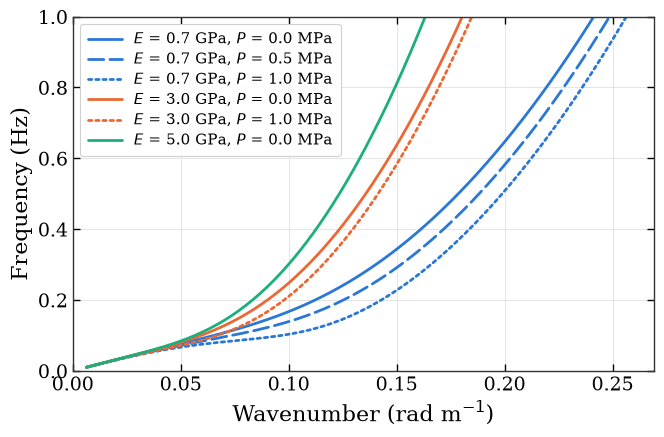

In [3]:
fig,ax_disp = plt.subplots(figsize=(7.5, 4.6))

# ---------------- dispersion curves ----------------
for E_GPa, P_MPa in CASES:
    ax_disp.plot(
        curves[(E_GPa, P_MPa)]["k"], FREQ,
        color=E_COLOR[E_GPa], linestyle=P_STYLE[P_MPa], lw=2.0,
        solid_capstyle="round", dash_capstyle="round",
        label=f"$E$ = {E_GPa:.1f} GPa, $P$ = {P_MPa:.1f} MPa",
    )

# Pad the k axis past the largest wavenumber reached by any case
k_max = np.nanmax([d["k"] for d in curves.values()])

ax_disp.set_xlabel("Wavenumber (rad m$^{-1}$)")
ax_disp.set_ylabel("Frequency (Hz)")
ax_disp.set_xlim(0.0, 1.05 * k_max)
ax_disp.set_ylim(0.0, FREQ[-1])
ax_disp.xaxis.set_major_locator(MultipleLocator(0.05))
ax_disp.yaxis.set_major_locator(MultipleLocator(0.2))
ax_disp.grid(True, color="0.88", lw=0.6)
ax_disp.set_axisbelow(True)
# Full box around the plotting area
for side in ("top", "right", "bottom", "left"):
    ax_disp.spines[side].set_visible(True)
    ax_disp.spines[side].set_linewidth(1.0)
    ax_disp.spines[side].set_color("0.2")
ax_disp.tick_params(direction="in", top=True, right=True, length=5, width=1.0)
ax_disp.legend(
    loc="upper left", fontsize=11, handlelength=2.2,
    labelspacing=0.3, borderaxespad=0.5, borderpad=0.5,
    frameon=True, facecolor="white", edgecolor="0.8", framealpha=0.92,
).get_frame().set_linewidth(0.8)

# ---------------- panel labels ----------------
fig.canvas.draw()
inv = fig.transFigure.inverted()
bb_disp = ax_disp.get_window_extent().transformed(inv)

fig.savefig(OUT_PDF, bbox_inches="tight", facecolor="white")
print(f"wrote {OUT_PDF.relative_to(PROJECT_ROOT)}")

plt.show()